# LAB12 — Stage 14 (Phase A): REST API, Docker Reuse, Automated Testing

**Kapsam: Phase A.** Stage 14 iki ayri yetkilendirilmis asamadan olusur:

- **Phase A (bu notebook'un kapsami):** FastAPI uygulamasi, Docker
  entegrasyonu, input/output contract'lari, API security & error
  handling, otomatik unit/integration testler, Stage 13 regresyon
  testleri, observability & performance benchmark, model artifact
  integrity & prediction parity, Pre-Test Freeze Manifest.
- **Phase B (bu notebook'ta YOK, Yetkilendirilmedi):** 2015 Protected
  Test'in acilmasi, okunmasi, degerlendirilmesi veya final evaluation
  komutunun calistirilmasi.

**Bu notebook, 2015 verisine hicbir noktada erismez.** Her hucre,
2006-2013 development-period bundle'i (Stage 13, M04-T003) veya sentetik
canary/test shipment'lari kullanir.

## Learning Objectives

1. Bir FastAPI servisinin, mevcut, dondurulmus bir inference component'i
   (`FreightCostPredictor`) NASIL reuse ettigini (reimplement etmeden)
   gormek.
2. Fail-closed startup/readiness tasarimini (bundle yuklenemezse servis
   traffic kabul etmez) canli olarak gozlemlemek.
3. Contract-based error handling'in (tek bir `{error_code, detail}`
   sekli, 422/500/503 mapping) nasil test edildigini gormek.
4. Docker'in NEDEN yeniden kullanildigini (ayri servis olusturulmadan)
   ve gercek bir `uvicorn` surecine host'tan nasil HTTP atildigini
   gormek.
5. Ayni ExtraTrees `n_jobs=2` floating-point davranisinin (Stage 13,
   D-154) HTTP katmaninda NASIL tekrar ortaya ciktigini (D-162) ve ayni
   tolerance politikasiyla nasil ele alindigini gormek.
6. Phase A'nin NEDEN "CONDITIONAL GO" ile bitip Phase B'nin acik onay
   gerektirdigini, somut kanitlarla (Final Report) gormek.

In [1]:
import sys
import json
import math
import platform
import subprocess
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

warnings.filterwarnings("ignore", category=DeprecationWarning)

LAB12_ROOT = Path.cwd() if (Path.cwd() / "api").exists() else Path.cwd() / "labs" / "lab12"
assert (LAB12_ROOT / "api" / "app.py").exists(), f"Could not locate labs/lab12 from {Path.cwd()}"
if str(LAB12_ROOT) not in sys.path:
    sys.path.insert(0, str(LAB12_ROOT))

ARTIFACT_DIR = LAB12_ROOT / "artifacts"
FIGURES_DIR = ARTIFACT_DIR / "figures" / "stage14"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RUNNING_IN_DOCKER = Path("/.dockerenv").exists()
ENV_KEY = "docker" if RUNNING_IN_DOCKER else "local"
print(f"LAB12_ROOT = {LAB12_ROOT}")
print(f"Running in Docker: {RUNNING_IN_DOCKER}  (environment key = '{ENV_KEY}')")
print(f"Python: {platform.python_version()}  Platform: {platform.platform()}")

LAB12_ROOT = /app/labs/lab12
Running in Docker: True  (environment key = 'docker')
Python: 3.11.18  Platform: Linux-6.18.33.1-microsoft-standard-WSL2-x86_64-with-glibc2.41


## Section 0 — Model Bundle Integrity Checkpoint (Before Any Phase A Work in This Run)

Stage 14 hicbir asamada modeli yeniden egitmez veya bundle'i degistirmez.
Bu hucre, bu notebook calistirilmadan once bundle'in Stage 13'ten
degismedigini dogrular -- Final Report'taki "Phase A basinda ve sonunda
ayni" iddiasinin kanitidir.

In [2]:
import hashlib

BUNDLE_VERSION_DIR = ARTIFACT_DIR / "stage13_model_bundle" / "v1"
model_path = BUNDLE_VERSION_DIR / "model.joblib"
manifest = json.loads((BUNDLE_VERSION_DIR / "manifest.json").read_text(encoding="utf-8"))

actual_sha256 = hashlib.sha256(model_path.read_bytes()).hexdigest()
expected_sha256 = manifest["model_artifact_sha256"]
assert actual_sha256 == expected_sha256, "Bundle integrity check FAILED -- model.joblib does not match its own manifest"
print(f"model_id={manifest['model_id']} trial_id={manifest['trial_id']} artifact_version={manifest['artifact_version']}")
print(f"model.joblib SHA-256 = {actual_sha256}")
print("Bundle integrity: CONFIRMED UNCHANGED since Stage 13.")

model_id=M04 trial_id=M04-T003 artifact_version=v1
model.joblib SHA-256 = 71a451344f8b88a8d440d90325b88668cd3a8c16379425f5a4e95061bed77782
Bundle integrity: CONFIRMED UNCHANGED since Stage 13.


## Section 1 — Startup & Readiness (Fail-Closed)

`FreightCostPredictor` tam olarak BIR KEZ, servis `lifespan` baslangicinda
yuklenir ve sabit bir canary shipment ile dogrulanir. `/health` (process
alive) ve `/ready` (bundle yuklendi mi) kasitli olarak AYRI endpoint'lerdir.

In [3]:
from fastapi.testclient import TestClient
from api.app import app

client = TestClient(app)
client.__enter__()  # triggers the lifespan startup (loads the real Stage 13 bundle, runs the canary)

health = client.get("/health")
ready = client.get("/ready")
print("GET /health ->", health.status_code, health.json())
print("GET /ready  ->", ready.status_code, ready.json())
assert health.status_code == 200 and ready.status_code == 200
assert ready.json()["model_id"] == "M04" and ready.json()["trial_id"] == "M04-T003"
print("\nStartup + readiness gate: PASSED (real bundle, real canary prediction).")

/opt/venv/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


GET /health -> 200 {'status': 'ok'}
GET /ready  -> 200 {'status': 'ready', 'model_id': 'M04', 'trial_id': 'M04-T003', 'artifact_version': 'v1'}

Startup + readiness gate: PASSED (real bundle, real canary prediction).


## Section 2 — Single Prediction

`POST /predict`, `FreightCostPredictor.predict_one()`'i dogrudan cagirir
(duplike validasyon yok, D-158).

In [4]:
valid_shipment = {
    "Line_Item_Qty_Sum": 500.0, "Line_Item_Value_Sum": 20000.0,
    "Shipment_Mode": "Air", "INCO_Term": "EXW", "Country": "Nigeria", "Product_Group": "ARV",
}

resp = client.post("/predict", json=valid_shipment)
print(resp.status_code)
print(json.dumps(resp.json(), indent=2))
assert resp.status_code == 200 and resp.json()["prediction_validity"] == "valid" 

200
{
  "model_id": "M04",
  "trial_id": "M04-T003",
  "model_version": "v1",
  "prediction_usd": 3727.512939580072,
  "prediction_validity": "valid",
  "uncertainty_status": "disabled",
  "explanation_status": "not_requested",
  "explanation": null,
  "risk_flags": [
    "UNVERIFIED_FEATURE_AVAILABILITY"
  ],
  "invalid_reason": null
}


## Section 3 — Batch Prediction & Atomic Validation

`POST /predict/batch`: tek bir satirin schema ihlali, TUM batch'i reddeder
(Stage 13, D-148) -- kismi basari yoktur.

In [5]:
batch = [dict(valid_shipment, Line_Item_Qty_Sum=float(q)) for q in (100, 500, 5000)]
batch_resp = client.post("/predict/batch", json=batch)
print(f"Valid batch of {len(batch)}: {batch_resp.status_code}")
for row in batch_resp.json():
    print(f"  qty={row}")

bad_batch = [valid_shipment, {**valid_shipment, "Country": None}, dict(valid_shipment)]
del bad_batch[-1]["Line_Item_Qty_Sum"]  # one structurally invalid row
atomic_resp = client.post("/predict/batch", json=bad_batch)
print(f"\nBatch with 1 bad row (of {len(bad_batch)}): {atomic_resp.status_code} -> {atomic_resp.json()}")
assert atomic_resp.status_code == 422
print("\nAtomic batch validation: CONFIRMED (one bad row rejects the whole batch, not just that row).")

Valid batch of 3: 200
  qty={'model_id': 'M04', 'trial_id': 'M04-T003', 'model_version': 'v1', 'prediction_usd': 3571.0840671621977, 'prediction_validity': 'valid', 'uncertainty_status': 'disabled', 'explanation_status': 'not_requested', 'explanation': None, 'risk_flags': ['UNVERIFIED_FEATURE_AVAILABILITY'], 'invalid_reason': None}
  qty={'model_id': 'M04', 'trial_id': 'M04-T003', 'model_version': 'v1', 'prediction_usd': 3727.5129395800723, 'prediction_validity': 'valid', 'uncertainty_status': 'disabled', 'explanation_status': 'not_requested', 'explanation': None, 'risk_flags': ['UNVERIFIED_FEATURE_AVAILABILITY'], 'invalid_reason': None}
  qty={'model_id': 'M04', 'trial_id': 'M04-T003', 'model_version': 'v1', 'prediction_usd': 5069.07035190299, 'prediction_validity': 'valid', 'uncertainty_status': 'disabled', 'explanation_status': 'not_requested', 'explanation': None, 'risk_flags': ['UNVERIFIED_FEATURE_AVAILABILITY'], 'invalid_reason': None}

Batch with 1 bad row (of 3): 422 -> {'error

## Section 4 — Error Contract (Section 10/11 of the Stage 14 Deployment Contract)

Her validasyon hatasi, TEK bir `{error_code, detail}` sekli ile 422
doner -- FastAPI'nin kendi otomatik validasyon formati devre disi (D-159).

In [6]:
error_scenarios = {
    "MISSING_REQUIRED_FIELD": {k: v for k, v in valid_shipment.items() if k != "Country"},
    "UNKNOWN_FIELD": dict(valid_shipment, Extra_Field="not-in-contract"),
    "INVALID_FIELD_TYPE": dict(valid_shipment, Line_Item_Qty_Sum="five-hundred"),
    "INVALID_NUMERIC_VALUE": dict(valid_shipment, Line_Item_Qty_Sum=-1),
}

rows = []
for expected_code, payload in error_scenarios.items():
    r = client.post("/predict", json=payload)
    body = r.json()
    rows.append({"scenario": expected_code, "status": r.status_code, "returned_error_code": body["error_code"], "match": body["error_code"] == expected_code})

error_table = pd.DataFrame(rows)
print(error_table.to_string(index=False))
assert error_table["match"].all()
print("\nAll error codes match the contract: CONFIRMED.")

              scenario  status    returned_error_code  match
MISSING_REQUIRED_FIELD     422 MISSING_REQUIRED_FIELD   True
         UNKNOWN_FIELD     422          UNKNOWN_FIELD   True
    INVALID_FIELD_TYPE     422     INVALID_FIELD_TYPE   True
 INVALID_NUMERIC_VALUE     422  INVALID_NUMERIC_VALUE   True

All error codes match the contract: CONFIRMED.


## Section 5 — Optional, Bounded Explainability

`explain=true`, default olarak KAPALI (D-150). Tek prediction icin
sinirsiz, batch icin `max_batch_explanations=10` ile sinirlidir (D-158
kapsaminda duplike edilmeyen, Stage 13'un kendi sinirlamasi).

In [7]:
from api.config import MAX_BATCH_EXPLANATIONS

explained = client.post("/predict", json=valid_shipment, params={"explain": "true"}).json()
print("explanation_status:", explained["explanation_status"])
print("additivity_valid:", explained["explanation"]["additivity_valid"], " diff_usd:", explained["explanation"]["additivity_diff_usd"])
print("top feature:", explained["explanation"]["feature_contributions"][0])

over_limit = client.post("/predict/batch", json=[valid_shipment] * (MAX_BATCH_EXPLANATIONS + 1), params={"explain": "true"})
print(f"\nbatch of {MAX_BATCH_EXPLANATIONS + 1} with explain=true -> {over_limit.status_code} {over_limit.json()['error_code']}")
assert over_limit.status_code == 422 and over_limit.json()["error_code"] == "EXPLANATION_BATCH_LIMIT_EXCEEDED"
print("\nExplainability bounding: CONFIRMED.")

explanation_status: available
additivity_valid: True  diff_usd: 2.319211489520967e-11
top feature: {'feature': 'Line_Item_Value_Sum', 'signed_contribution_usd': -4133.719639223431, 'absolute_contribution_usd': 4133.719639223431}

batch of 11 with explain=true -> 422 EXPLANATION_BATCH_LIMIT_EXCEEDED

Explainability bounding: CONFIRMED.


## Section 6 — Interval Policy: `request_interval=true` Never Returns Bounds

Stage 12'nin "Production Interval Not Approved" karari (D-153), API
katmaninda BYPASS EDILMEZ -- sadece bir risk flag eklenir, hicbir
zaman lower/upper bound uretilmez.

In [8]:
interval_resp = client.post("/predict", json=valid_shipment, params={"request_interval": "true"}).json()
print(json.dumps(interval_resp, indent=2))
assert "INTERVAL_NOT_APPROVED" in interval_resp["risk_flags"]
assert not any(k in interval_resp for k in ("lower_bound_usd", "upper_bound_usd", "interval"))
print("\nInterval non-disclosure policy: CONFIRMED -- no bounds ever returned.")

{
  "model_id": "M04",
  "trial_id": "M04-T003",
  "model_version": "v1",
  "prediction_usd": 3727.512939580072,
  "prediction_validity": "valid",
  "uncertainty_status": "disabled",
  "explanation_status": "not_requested",
  "explanation": null,
  "risk_flags": [
    "INTERVAL_NOT_APPROVED",
    "UNVERIFIED_FEATURE_AVAILABILITY"
  ],
  "invalid_reason": null
}

Interval non-disclosure policy: CONFIRMED -- no bounds ever returned.


## Section 7 — Security: No Arbitrary Model Path (Contract Section 15)

Bundle yolu `api/config.py` icinde SABIT bir degerdir -- ne request
body'si, ne query parametresi, ne environment variable bunu
degistirebilir.

In [9]:
from api import config

tampered = dict(valid_shipment, model_path="/etc/passwd", bundle_path="../../../etc")
r = client.post("/predict", json=tampered)
print(f"body field override attempt -> {r.status_code} {r.json()['error_code']}")
assert r.status_code == 422 and r.json()["error_code"] == "UNKNOWN_FIELD"

r = client.post("/predict", json=valid_shipment, params={"bundle_path": "../../etc/passwd"})
print(f"query param override attempt -> {r.status_code} (ignored, served normally: {r.json()['model_id']})")
assert r.status_code == 200

print(f"\nFixed BUNDLE_VERSION_DIR = {config.BUNDLE_VERSION_DIR}")
print(f"Fixed BUNDLE_ROOT        = {config.BUNDLE_ROOT}")
print("\nNo arbitrary model path acceptance: CONFIRMED.")

body field override attempt -> 422 UNKNOWN_FIELD


query param override attempt -> 200 (ignored, served normally: M04)

Fixed BUNDLE_VERSION_DIR = /app/labs/lab12/artifacts/stage13_model_bundle/v1
Fixed BUNDLE_ROOT        = /app/labs/lab12/artifacts/stage13_model_bundle

No arbitrary model path acceptance: CONFIRMED.


## Section 8 — Model Parity: API Output == Direct `FreightCostPredictor` Output

Contract Section 17: API'nin dondurdugu `prediction_usd`, EK bir
rounding/transformasyon icermemelidir. Tolerance, D-162'nin kapsadigi
~1e-13 USD floating-point noise icin 1e-6 USD'dir (Stage 13'un D-154
politikasiyla TUTARLI).

In [10]:
from api.config import BUNDLE_ROOT, EXPECTED_MODEL_ID, EXPECTED_TRIAL_ID
from inference.predictor import FreightCostPredictor

direct_predictor = FreightCostPredictor.load(
    bundle_dir=BUNDLE_VERSION_DIR, allowed_root=BUNDLE_ROOT,
    expected_model_id=EXPECTED_MODEL_ID, expected_trial_id=EXPECTED_TRIAL_ID,
)
direct_result = direct_predictor.predict_one(valid_shipment).to_dict()
api_result = client.post("/predict", json=valid_shipment).json()

diff_usd = abs(api_result["prediction_usd"] - direct_result["prediction_usd"])
print(f"API prediction_usd:    {api_result['prediction_usd']}")
print(f"Direct prediction_usd: {direct_result['prediction_usd']}")
print(f"Diff: {diff_usd:.2e} USD (tolerance: 1e-6 USD)")
assert diff_usd < 1e-6
assert {k: v for k, v in api_result.items() if k != "prediction_usd"} == {k: v for k, v in direct_result.items() if k != "prediction_usd"}
print("\nModel parity (within documented floating-point tolerance): CONFIRMED.")

API prediction_usd:    3727.5129395800723
Direct prediction_usd: 3727.512939580072
Diff: 4.55e-13 USD (tolerance: 1e-6 USD)

Model parity (within documented floating-point tolerance): CONFIRMED.


## Section 9 — Automated Test Suite (This Environment)

Stage 13 regresyon testleri (degismedi) + Stage 14'un yeni testleri,
`pytest` ile bu notebook'un calistigi ortamda (local veya Docker)
calistirilir.

In [11]:
client.__exit__(None, None, None)  # release before pytest spins up its own TestClient/app instances

test_proc = subprocess.run(
    [sys.executable, "-m", "pytest", str(LAB12_ROOT / "tests" / "stage13"), str(LAB12_ROOT / "tests" / "stage14"), "-q", "--color=no"],
    capture_output=True, text=True, cwd=str(LAB12_ROOT.parent.parent),
)
print(test_proc.stdout[-3000:])
if test_proc.returncode != 0:
    print(test_proc.stderr[-2000:])

summary_line = [line for line in test_proc.stdout.splitlines() if "passed" in line or "failed" in line][-1]
print(f"\nSUMMARY ({ENV_KEY}): {summary_line}")

results_path = ARTIFACT_DIR / "stage14_test_results_by_environment.json"
results = json.loads(results_path.read_text(encoding="utf-8")) if results_path.exists() else {}
results[ENV_KEY] = {"python_version": platform.python_version(), "summary": summary_line, "returncode": test_proc.returncode}
results_path.write_text(json.dumps(results, indent=2), encoding="utf-8")
print(f"\nWrote {results_path.name}: {json.dumps(results, indent=2)}")

........................................................................ [ 80%]
..................                                                       [100%]
=============================== warnings summary ===============================
../opt/venv/lib/python3.11/site-packages/shap/plots/colors/_colors.py:47
  /opt/venv/lib/python3.11/site-packages/shap/plots/colors/_colors.py:47: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
    red_blue.set_bad(gray_rgb.tolist(), 1.0)

../opt/venv/lib/python3.11/site-packages/shap/plots/colors/_colors.py:48
  /opt/venv/lib/python3.11/site-packages/shap/plots/colors/_colors.py:48: PendingDeprecationWarning: The set_over function will be deprecated in a future version. Use cmap.with_extremes(over=...) or Colormap(over=...) instead.
    red_blue.set_over(gray_rgb.tolist(), 1.0)

../opt/venv/lib/python3.11/site-packages/shap/plots/colors/_colors.py

## Section 10 — Performance Benchmark (Observability)

Latency, gercek bundle'a karsi `TestClient` (in-process ASGI) uzerinden
olculur -- tek kullanicili, sirali cagrilar. Sonuclar, calistirma
ortamina gore (`local`/`docker`) ayri bir anahtar altinda birikerek
kaydedilir, boylece bu notebook iki ortamda da calistirildiginda
kars.ilastirma mumkun olur.

In [12]:
import statistics as stats

with TestClient(app) as bench_client:
    def bench(fn, n=30):
        times = []
        for _ in range(n):
            t0 = time.perf_counter()
            fn()
            times.append((time.perf_counter() - t0) * 1000)
        times.sort()
        return {"n": n, "mean_ms": round(stats.mean(times), 3), "p50_ms": round(times[len(times) // 2], 3), "p95_ms": round(times[int(len(times) * 0.95)], 3)}

    bench_results = {
        "single_no_explain": bench(lambda: bench_client.post("/predict", json=valid_shipment), n=40),
        "single_with_explain": bench(lambda: bench_client.post("/predict", json=valid_shipment, params={"explain": "true"}), n=40),
        "batch_1_no_explain": bench(lambda: bench_client.post("/predict/batch", json=[valid_shipment]), n=20),
        "batch_10_no_explain": bench(lambda: bench_client.post("/predict/batch", json=[valid_shipment] * 10), n=20),
        "batch_100_no_explain": bench(lambda: bench_client.post("/predict/batch", json=[valid_shipment] * 100), n=20),
        "batch_10_with_explain": bench(lambda: bench_client.post("/predict/batch", json=[valid_shipment] * 10, params={"explain": "true"}), n=20),
    }

bench_df = pd.DataFrame(bench_results).T
print(bench_df)

bench_path = ARTIFACT_DIR / "stage14_performance_benchmark.json"
bench_artifact = json.loads(bench_path.read_text(encoding="utf-8")) if bench_path.exists() else {}
bench_artifact[ENV_KEY] = {"python_version": platform.python_version(), "method": "FastAPI TestClient, in-process ASGI, real Stage 13 bundle", "results": bench_results}
bench_path.write_text(json.dumps(bench_artifact, indent=2), encoding="utf-8")
print(f"\nWrote {bench_path.name} (updated '{ENV_KEY}' section).")

                          n  mean_ms   p50_ms   p95_ms
single_no_explain      40.0   69.162   72.218   74.875
single_with_explain    40.0   76.127   74.815   83.479
batch_1_no_explain     20.0   64.205   63.565   74.592
batch_10_no_explain    20.0   66.472   64.345   75.389
batch_100_no_explain   20.0   68.173   64.389   89.466
batch_10_with_explain  20.0  175.523  173.949  206.869

Wrote stage14_performance_benchmark.json (updated 'docker' section).


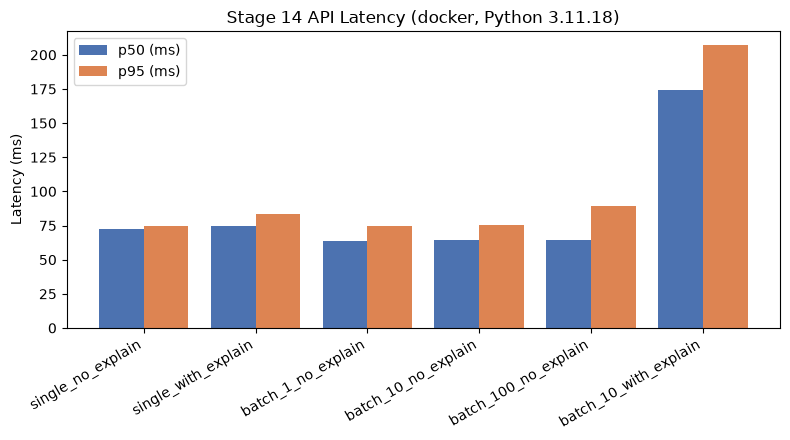

Saved /app/labs/lab12/artifacts/figures/stage14/fig01_api_latency_docker.png


In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = list(bench_results.keys())
p50 = [bench_results[k]["p50_ms"] for k in labels]
p95 = [bench_results[k]["p95_ms"] for k in labels]
x = range(len(labels))
ax.bar([i - 0.2 for i in x], p50, width=0.4, label="p50 (ms)", color="#4C72B0")
ax.bar([i + 0.2 for i in x], p95, width=0.4, label="p95 (ms)", color="#DD8452")
ax.set_xticks(list(x))
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_ylabel("Latency (ms)")
ax.set_title(f"Stage 14 API Latency ({ENV_KEY}, Python {platform.python_version()})")
ax.legend()
fig.tight_layout()
fig_path = FIGURES_DIR / f"fig01_api_latency_{ENV_KEY}.png"
fig.savefig(fig_path, dpi=120)
plt.show()
print(f"Saved {fig_path}")

**Gercek bulgu (D-163):** `batch_1` ile `batch_100` arasindaki p50
latency farki, batch size'in kendisinden degil, sabit bir per-call
overhead'den kaynaklaniyor -- yukarida bu iki cubugun boyunun yaklasik
ayni oldugunu gorebilirsiniz. `explain=true`, satir basina belirgin bir
ek maliyet getiriyor (bkz `batch_10_with_explain`).

## Section 11 — Cross-Environment Prediction Parity (Local <-> Docker, Real HTTP)

Bu hucre, canary shipment'i bu notebook'un calistigi ortamda API
uzerinden tahmin eder ve sonucu, diger ortamdan (varsa) onceden
kaydedilmis sonucla karsilastirir -- Stage 13'un D-155 parity testinin
API katmanindaki karsiligi.

In [14]:
with TestClient(app) as parity_client:
    canary_result = parity_client.post("/predict", json=valid_shipment).json()

parity_path = ARTIFACT_DIR / "stage14_cross_environment_parity.json"
parity = json.loads(parity_path.read_text(encoding="utf-8")) if parity_path.exists() else {}
parity[ENV_KEY] = {"python_version": platform.python_version(), "prediction_usd": canary_result["prediction_usd"], "bundle_sha256": manifest["model_artifact_sha256"]}
parity_path.write_text(json.dumps(parity, indent=2), encoding="utf-8")

print(f"This run ({ENV_KEY}): prediction_usd = {canary_result['prediction_usd']}")
if "local" in parity and "docker" in parity:
    diff = abs(parity["local"]["prediction_usd"] - parity["docker"]["prediction_usd"])
    same_bundle = parity["local"]["bundle_sha256"] == parity["docker"]["bundle_sha256"]
    print(f"local={parity['local']['prediction_usd']}  docker={parity['docker']['prediction_usd']}  diff={diff:.2e} USD")
    print(f"Same bundle SHA-256 across environments: {same_bundle}")
    assert diff < 1e-6 and same_bundle
    print("\nCross-environment parity: CONFIRMED (within 1e-6 USD tolerance, same bundle).")
else:
    print(f"\nWaiting on the other environment's run to complete the comparison (have: {list(parity.keys())}).")

This run (docker): prediction_usd = 3727.512939580072
local=3727.5129395800723  docker=3727.512939580072  diff=4.55e-13 USD
Same bundle SHA-256 across environments: True

Cross-environment parity: CONFIRMED (within 1e-6 USD tolerance, same bundle).


## Section 12 — Pre-Test Freeze Manifest

Phase B (2015 Protected Test) baslamadan ONCE, sistemin dondurulmus
durumunu kayit altina alir. **Bu hucre Phase B'yi TETIKLEMEZ, baslatmaz,
veya 2015 verisine erismez** -- sadece Phase A'nin bitimindeki durumu
imzalar.

In [15]:
freeze_path = ARTIFACT_DIR / "stage14_pretest_freeze_manifest.json"
existing_test_results = json.loads((ARTIFACT_DIR / "stage14_test_results_by_environment.json").read_text(encoding="utf-8"))
existing_parity = json.loads((ARTIFACT_DIR / "stage14_cross_environment_parity.json").read_text(encoding="utf-8"))

freeze_manifest = {
    "freeze_timestamp_utc": pd.Timestamp.utcnow().isoformat(),
    "phase": "Phase A complete, Phase B not authorized",
    "created_from": "lab12_stage14_api_deployment.ipynb",
    "model_bundle": {
        "path": str(BUNDLE_VERSION_DIR.relative_to(LAB12_ROOT.parent.parent)).replace("\\", "/"),
        "model_id": manifest["model_id"], "trial_id": manifest["trial_id"], "artifact_version": manifest["artifact_version"],
        "model_artifact_sha256": actual_sha256,
        "verified_unchanged": actual_sha256 == expected_sha256,
    },
    "api_layer": {
        "package": "labs/lab12/api/", "modules": ["__init__.py", "config.py", "schemas.py", "errors.py", "app.py"],
        "endpoints": ["GET /health", "GET /ready", "POST /predict", "POST /predict/batch"],
        "bundle_path_policy": "hardcoded in api/config.py; not derived from any request, header, query parameter, or environment variable",
        "docker_topology_decision": "reused the existing ml-lab service; no new Docker service created (D-157)",
    },
    "test_results_by_environment": existing_test_results,
    "cross_environment_prediction_parity": existing_parity,
    "real_findings_during_phase_a": [
        "D-162: ExtraTrees n_jobs=2 thread-order-dependent floating-point noise (~1e-13 USD), same root cause as Stage 13 D-154, now also observed at the API layer -- tolerance-based assertions used.",
        "D-163: API latency is dominated by a fixed per-call overhead, essentially flat from batch size 1 to 100; explain=true adds a measurable per-row cost.",
    ],
    "protected_test_policy": {
        "accessed_in_phase_a": False,
        "statement": "The 2015 Protected Test was not opened, read, parsed, scored, or referenced by any code, test, or notebook cell written during Stage 14 Phase A.",
    },
    "phase_b_readiness": "CONDITIONAL GO",
}

freeze_path.write_text(json.dumps(freeze_manifest, indent=2, default=str), encoding="utf-8")
print(f"Wrote {freeze_path.name}")
print(json.dumps(freeze_manifest, indent=2, default=str))

Wrote stage14_pretest_freeze_manifest.json
{
  "freeze_timestamp_utc": "2026-11-24T07:37:28.653960+00:00",
  "phase": "Phase A complete, Phase B not authorized",
  "created_from": "lab12_stage14_api_deployment.ipynb",
  "model_bundle": {
    "path": "labs/lab12/artifacts/stage13_model_bundle/v1",
    "model_id": "M04",
    "trial_id": "M04-T003",
    "artifact_version": "v1",
    "model_artifact_sha256": "71a451344f8b88a8d440d90325b88668cd3a8c16379425f5a4e95061bed77782",
    "verified_unchanged": true
  },
  "api_layer": {
    "package": "labs/lab12/api/",
    "modules": [
      "__init__.py",
      "config.py",
      "schemas.py",
      "errors.py",
      "app.py"
    ],
    "endpoints": [
      "GET /health",
      "GET /ready",
      "POST /predict",
      "POST /predict/batch"
    ],
    "bundle_path_policy": "hardcoded in api/config.py; not derived from any request, header, query parameter, or environment variable",
    "docker_topology_decision": "reused the existing ml-lab servi

## Section 13 — Phase A Final Report & STOP

**Bu notebook Phase A kapsamindadir.** Phase B (2015 Protected Test final
evaluation), kullanicinin ayri ve acik onayi olmadan baslatilmaz. Tam rapor: `docs/stage14_phase_a_final_report.md`.

In [16]:
print("=" * 70)
print("STAGE 14 PHASE A -- FINAL STATUS")
print("=" * 70)
print(f"Model bundle unchanged:        {freeze_manifest['model_bundle']['verified_unchanged']}")
print(f"Environments validated:        {list(existing_test_results.keys())}")
for env, result in existing_test_results.items():
    print(f"  [{env}] {result['summary']}")
print(f"2015 Protected Test accessed:  {freeze_manifest['protected_test_policy']['accessed_in_phase_a']}")
print(f"Phase B readiness:             {freeze_manifest['phase_b_readiness']}")
print("=" * 70)
print("PHASE A COMPLETE. STOPPING HERE.")
print("Phase B (2015 Protected Test) requires separate, explicit user approval.")
print("=" * 70)

STAGE 14 PHASE A -- FINAL STATUS
Model bundle unchanged:        True
Environments validated:        ['local', 'docker']
  [local] 90 passed, 4 warnings in 9.99s
  [docker] 90 passed, 4 warnings in 18.31s
2015 Protected Test accessed:  False
Phase B readiness:             CONDITIONAL GO
PHASE A COMPLETE. STOPPING HERE.
Phase B (2015 Protected Test) requires separate, explicit user approval.
